In [5]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'ice-cream-sales-dataset' dataset.
Path to dataset files: /kaggle/input/ice-cream-sales-dataset


In [6]:
import os
import pandas as pd

# Listar arquivos no diretório do dataset
files = os.listdir(path)
print("Arquivos encontrados:", files)

# Encontrar e carregar o arquivo CSV
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"\nDataset '{csv_files[0]}' carregado com sucesso!")
    display(df.head())
else:
    print("Nenhum arquivo CSV encontrado no diretório do dataset.")

Arquivos encontrados: ['Ice Cream.csv']

Dataset 'Ice Cream.csv' carregado com sucesso!


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


Colunas do dataset: ['Temperature', 'Revenue']

Gerando gráfico de dispersão com regressão linear: 'Temperature' vs 'Revenue'


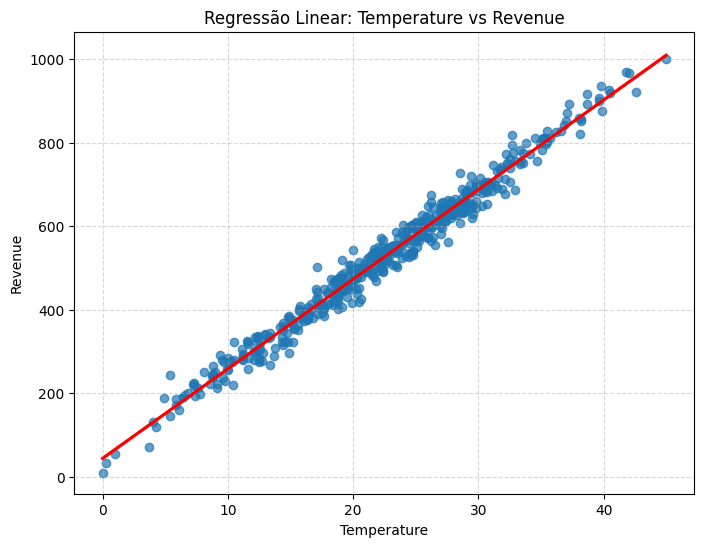

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Verificar as colunas disponíveis para escolher as variáveis do gráfico
print("Colunas do dataset:", df.columns.tolist())

# Identificar colunas numéricas para o gráfico de dispersão (normalmente Temperatura vs Vendas)
x_col = df.select_dtypes(include=['number']).columns[0]
y_col = df.select_dtypes(include=['number']).columns[1] if len(df.select_dtypes(include=['number']).columns) > 1 else df.columns[-1]

print(f"\nGerando gráfico de dispersão com regressão linear: '{x_col}' vs '{y_col}'")

plt.figure(figsize=(8, 6))
sns.regplot(data=df, x=x_col, y=y_col, scatter_kws={'alpha':0.7}, line_kws={'color':'red'})
plt.title(f'Regressão Linear: {x_col} vs {y_col}')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [8]:
from sklearn.linear_model import LinearRegression

# Preparar as variáveis X e y
X = df[['Temperature']]
y = df['Revenue']

# Inicializar e ajustar o modelo de Regressão Linear
model = LinearRegression()
model.fit(X, y)

# Extrair os coeficientes
inclinacao = model.coef_[0]
intercepto = model.intercept_

print(f"Coeficiente Angular (Inclinação / Slope): {inclinacao:.4f}")
print(f"Coeficiente Linear (Intercepto / Intercept): {intercepto:.4f}")
print(f"\nEquação da reta: Receita = {inclinacao:.4f} * Temperatura + ({intercepto:.4f})")

Coeficiente Angular (Inclinação / Slope): 21.4420
Coeficiente Linear (Intercepto / Intercept): 44.2968

Equação da reta: Receita = 21.4420 * Temperatura + (44.2968)
